In [394]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import logging

from scipy.stats import spearmanr, pearsonr
from numpy.linalg import norm
import matplotlib.pyplot as plt

from gt_concepts.shapley import exact_shapley_value, montecarlo_shapley_value
from gt_concepts.least_core import exact_least_core, montecarlo_least_core, ValuationResult
from gt_concepts.nucleolus import montecarlo_nucleolus, exact_nucleolus
from gt_concepts.banzhaf import exact_banzhaf_index, montecarlo_banzhaf_index
from gt_concepts.shapley_shubik import exact_shapley_shubik, montecarlo_shapley_shubik
from gt_concepts.gately_point import exact_gately_value
from gt_concepts.deegan_packel import exact_deegan_packel_index, montecarlo_deegan_packel_index
from models.train_model import get_model
from utils.plotting import plot_single_valuation
from utils.evaluation import evaluate_model

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

In [ ]:
DATASET_NAME = ""
MODEL_NAME = "logistic"
SCORING = "accuracy"
METHODS = ["shapley","least_core","nucleolus","banzhaf", "shapley_shubik","gately" ]
MONTE_CARLO = False
N_MC_ITERATIONS = 10000
RANDOM_STATE = 42

OUTPUT_DIR = Path(f"./output/feature_valuation/{DATASET_NAME}_{MODEL_NAME}_{SCORING}_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [446]:
def load_dataset(name: str):
    path_map = {
        "breast_cancer": "/Users/rohitsuresh/Desktop/CGT_Explainability/datasets/breast_cancer/breast_cancer_preprocessed.npz",
        "congress": "../datasets/congress/congress_preprocessed.npz",
        "wine": "/Users/rohitsuresh/Desktop/CGT_Explainability/datasets/wine/wine_preprocessed.npz",
        "apple_quality": "../datasets/apple_quality/apple_quality_preprocessed_no_scaling.npz",
        "yield_synthetic": "/Users/rohitsuresh/Desktop/CGT_Explainability/datasets/yield_synthetic/yield_preprocessed.npz"
    }
    path = Path(path_map[name])
    data = np.load(path, allow_pickle=True)
    feature_names = data["feature_names"].tolist() if "feature_names" in data else [f"f{i}" for i in range(data["X_train"].shape[1])]
    return data["X_train"], data["X_test"], data["y_train"], data["y_test"], feature_names

In [447]:
class DataWrapper:
    def __init__(self, indices, names=None):
        self.indices = indices
        self.data_names = names if names is not None else [f"f{i}" for i in range(len(indices))]

    def __len__(self):
        return len(self.indices)

    def __iter__(self):
        return iter(self.indices)

class Utility:
    def __init__(self, X_train, y_train, X_test, y_test, model_name, scorer, feature_names=None, random_state=42):
        self.X_train = X_train
        self.y_train = y_train
        self.X_test = X_test
        self.y_test = y_test
        self.model_name = model_name
        self.scorer = scorer
        self.data = DataWrapper(list(range(X_train.shape[1])), feature_names)
        self.random_state = random_state
        self._cache = {}

    def __call__(self, subset):
        key = tuple(sorted(subset))
        if key in self._cache:
            return self._cache[key]
        if len(key) == 0:
            majority = np.bincount(self.y_train.astype(int)).argmax()
            y_pred = np.full_like(self.y_test, majority)
            score = self.scorer(self.y_test, y_pred)
            self._cache[key] = score
            return score
        model = get_model(self.model_name, self.random_state)
        model.fit(self.X_train[:, key], self.y_train)
        y_pred = model.predict(self.X_test[:, key])
        score = self.scorer(self.y_test, y_pred)
        self._cache[key] = score
        return score

In [448]:
from sklearn.metrics import accuracy_score, f1_score, mean_squared_error, r2_score, mean_absolute_error

def get_scorer(name):
    if name == "accuracy":
        return lambda y_true, y_pred: accuracy_score(y_true, y_pred)
    elif name == "f1_macro":
        return lambda y_true, y_pred: f1_score(y_true, y_pred, average="macro")
    elif name == "r2":
        return lambda y_true, y_pred: r2_score(y_true, y_pred)
    elif name == "mse":
        return lambda y_true, y_pred: -mean_squared_error(y_true, y_pred)
    elif name == "rmse":
        return lambda y_true, y_pred: -np.sqrt(mean_squared_error(y_true, y_pred))
    elif name == "mae":
        return lambda y_true, y_pred: -mean_absolute_error(y_true, y_pred)
    else:
        raise ValueError(f"Unknown scorer: {name}")

In [449]:
X_train, X_test, y_train, y_test, feature_names = load_dataset(DATASET_NAME)
scorer = get_scorer(SCORING)
utility = Utility(
    X_train, y_train, X_test, y_test,
    MODEL_NAME,
    scorer,
    feature_names=feature_names,
    random_state=RANDOM_STATE
)

n_features = X_train.shape[1]
full_model_accuracy = utility(list(range(n_features)))
SHAPLEY_SHUBIK_THRESHOLD = full_model_accuracy / (1* n_features)

In [450]:
full_model_accuracy

0.86

In [451]:
n_features

4

In [452]:
SHAPLEY_SHUBIK_THRESHOLD

0.215

In [453]:
results = {}
use_exact = not MONTE_CARLO
if "shapley" in METHODS:
    val = exact_shapley_value(utility) if use_exact else montecarlo_shapley_value(utility, N_MC_ITERATIONS)
    results["shapley"] = val.values
if "least_core" in METHODS:
    val = exact_least_core(utility) if use_exact else montecarlo_least_core(utility, N_MC_ITERATIONS)
    results["least_core"] = val.values
if "nucleolus" in METHODS:
    val = exact_nucleolus(utility, N_MC_ITERATIONS) if use_exact else montecarlo_nucleolus(utility, N_MC_ITERATIONS)
    results["nucleolus"] = val.values if val is not None else None
if "banzhaf" in METHODS:
    val = exact_banzhaf_index(utility, SHAPLEY_SHUBIK_THRESHOLD) if use_exact else montecarlo_banzhaf_index(utility, N_MC_ITERATIONS, normalized=True)
    results["banzhaf"] = val.values
if "shapley_shubik" in METHODS:
    val = exact_shapley_shubik(utility, SHAPLEY_SHUBIK_THRESHOLD) if use_exact else montecarlo_shapley_shubik(utility, N_MC_ITERATIONS)
    results["shapley_shubik"] = val.values
if "gately" in METHODS:
    val = exact_gately_value(utility) if use_exact else montecarlo_gately_value(utility, N_MC_ITERATIONS)
    results["gately"] = val.values
if "deegan_packel" in METHODS:
    baseline = utility([])
    full_model_accuracy = utility(range(X_train.shape[1]))
    threshhold = full_model_accuracy
    val = exact_deegan_packel_index(utility, threshhold,normalized=True) if use_exact else montecarlo_deegan_packel_index(utility, N_MC_ITERATIONS, normalized=True)
    results["deegan_packel"] = val.values
df = pd.DataFrame([
    {"method": m, "feature": feature_names[i], "value": v}
    for m, vals in results.items() for i, v in enumerate(vals)
])
df.head()

,method,feature,value
0,shapley,Nitrogen,0.083750
1,shapley,Irrigation,0.327917
2,shapley,Precipitation,0.109583
3,shapley,Herbicide,0.018750
4,least_core,Nitrogen,0.167500


In [454]:
print(df)
print(utility.data.data_names)

            method        feature     value
0          shapley       Nitrogen  0.083750
1          shapley     Irrigation  0.327917
2          shapley  Precipitation  0.109583
3          shapley      Herbicide  0.018750
4       least_core       Nitrogen  0.167500
5       least_core     Irrigation  0.407500
6       least_core  Precipitation  0.177500
7       least_core      Herbicide  0.107500
8        nucleolus       Nitrogen  0.167500
9        nucleolus     Irrigation  0.407500
10       nucleolus  Precipitation  0.177500
11       nucleolus      Herbicide  0.107500
12         banzhaf       Nitrogen  0.143038
13         banzhaf     Irrigation  0.639241
14         banzhaf  Precipitation  0.196203
15         banzhaf      Herbicide  0.021519
16  shapley_shubik       Nitrogen  0.000000
17  shapley_shubik     Irrigation  0.000000
18  shapley_shubik  Precipitation  0.000000
19  shapley_shubik      Herbicide  0.000000
20          gately       Nitrogen  0.166457
21          gately     Irrigatio

In [455]:
df.to_csv(OUTPUT_DIR / f"{DATASET_NAME}_{MODEL_NAME}_feature_valuations.csv", index=False)

In [456]:
model_accurcy = utility(range(X_train.shape[1]))
print(f"Model accuracy with all features: {model_accurcy:.4f}")

Model accuracy with all features: 0.8600


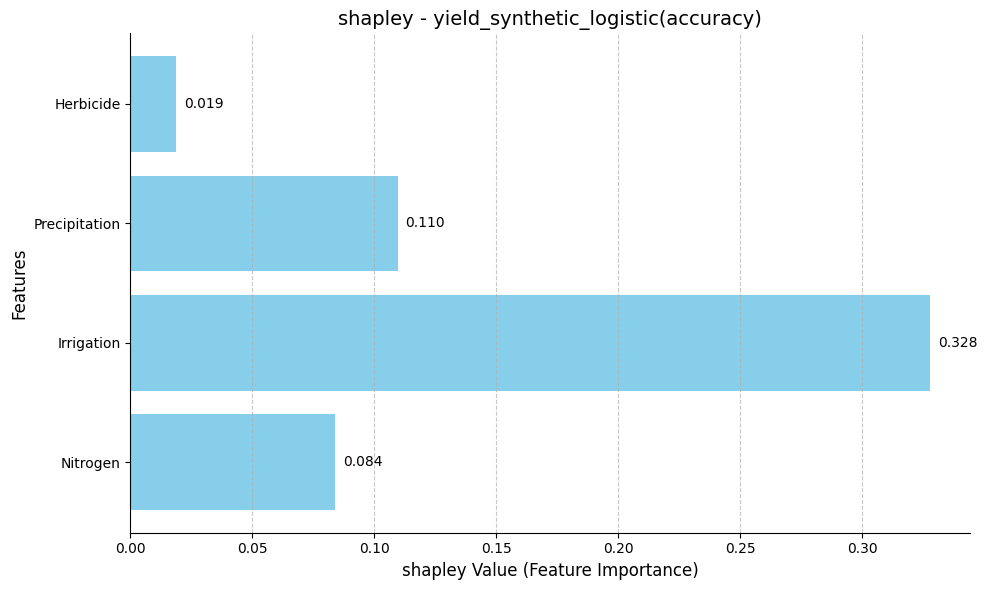

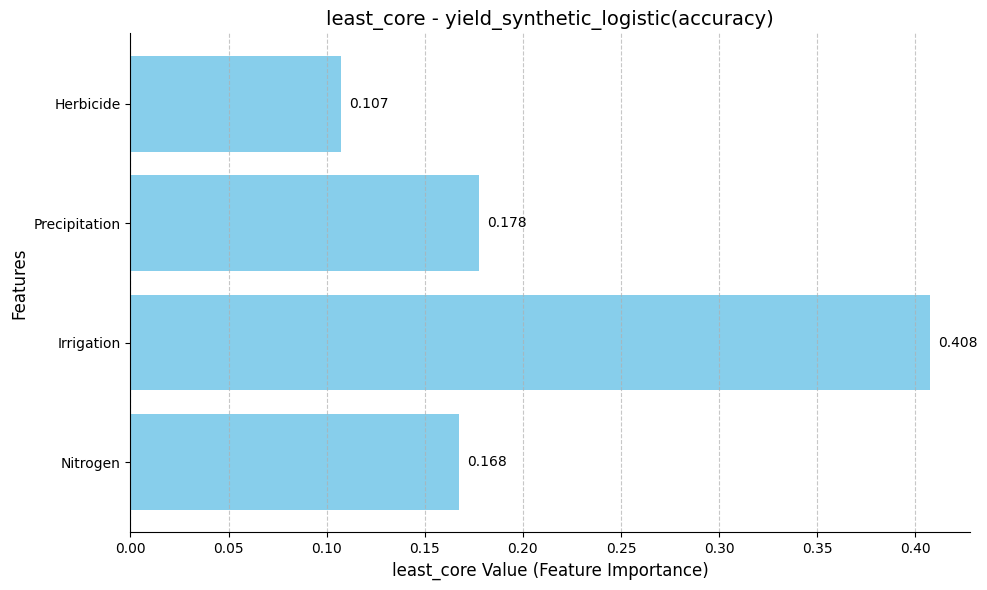

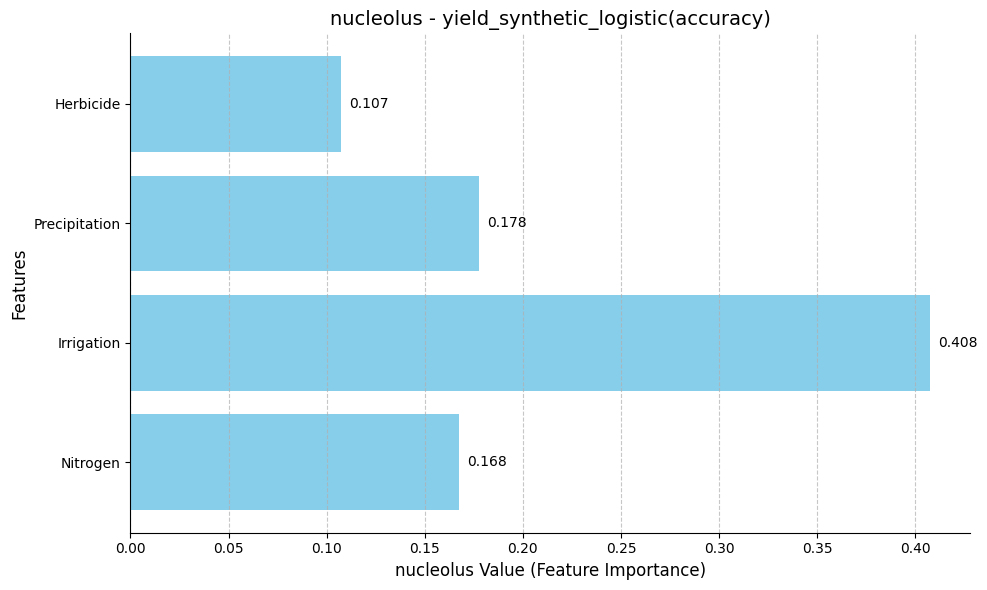

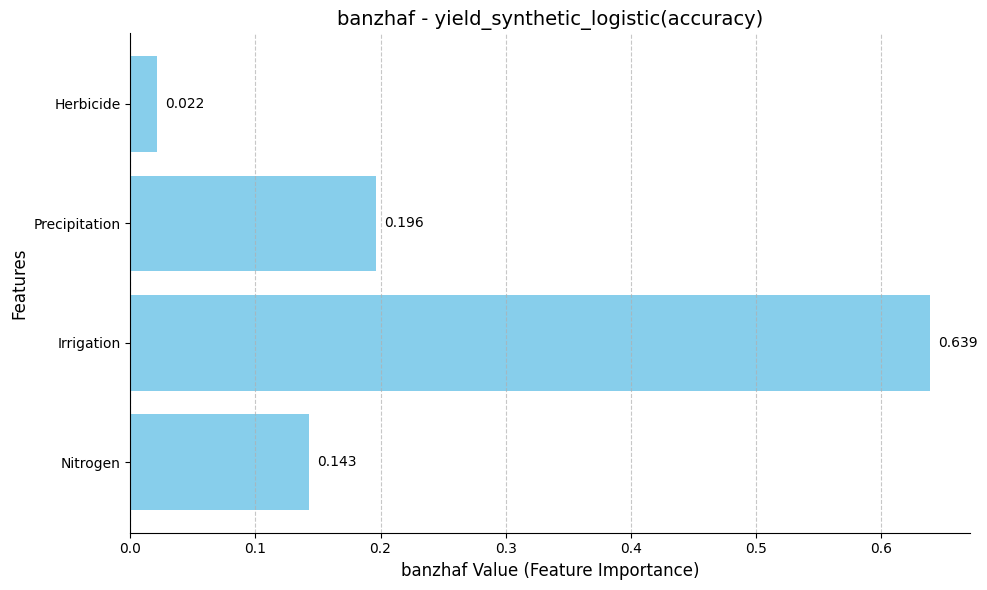

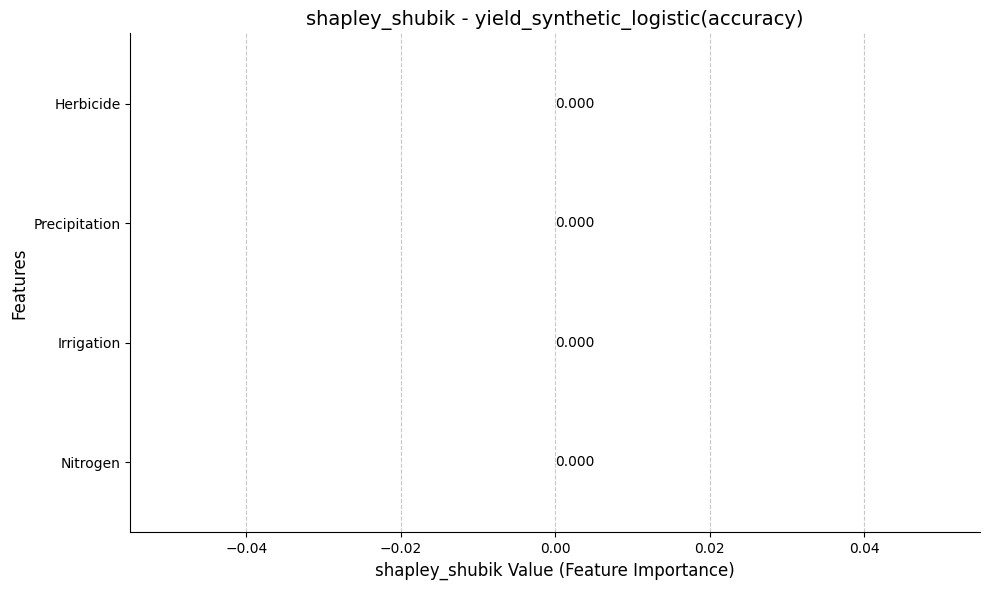

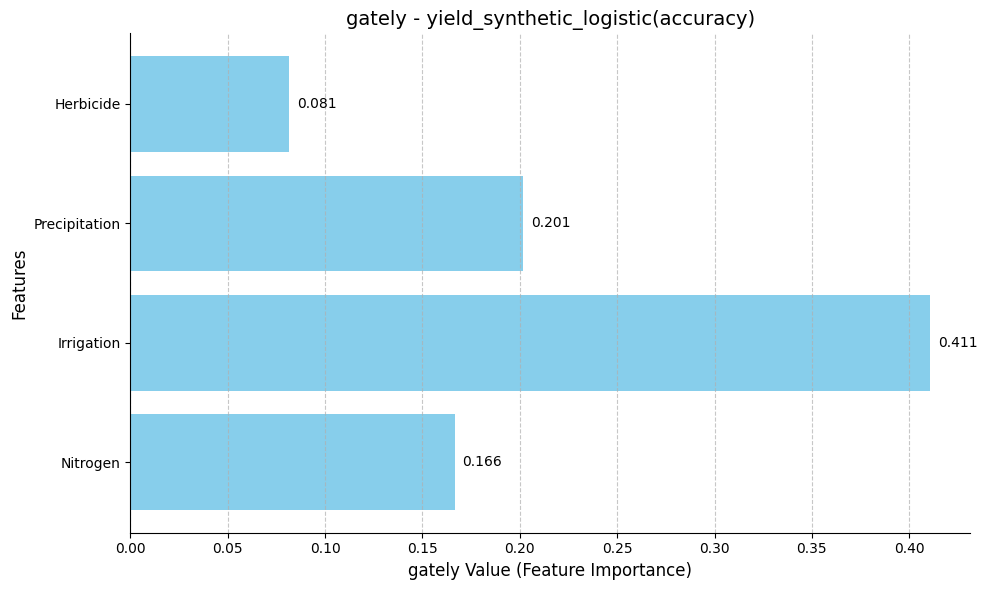

In [457]:
for method, vals in results.items():
    plot_single_valuation(
        vals, feature_names,
        method_name=method,
        title=f"{method} - {DATASET_NAME}_{MODEL_NAME}({SCORING})",
        output_path=OUTPUT_DIR / f"{DATASET_NAME}_{MODEL_NAME}_{method}_{SCORING}.png"
    )

In [458]:
from scipy.stats import spearmanr

methods = df["method"].unique()
rank_corr = pd.DataFrame(index=methods, columns=methods)
rankings = {m: df[df["method"] == m].sort_values("value", ascending=False)["feature"].tolist() for m in methods}

for m1 in methods:
    for m2 in methods:
        if m1 == m2:
            rank_corr.loc[m1, m2] = 1.0
        else:
            common = set(rankings[m1]) & set(rankings[m2])
            r1 = [rankings[m1].index(f) for f in common]
            r2 = [rankings[m2].index(f) for f in common]
            corr, _ = spearmanr(r1, r2)
            rank_corr.loc[m1, m2] = corr

rank_corr

,shapley,least_core,nucleolus,banzhaf,shapley_shubik,gately
shapley,1.0,1.0,1.0,1.0,0.4,1.0
least_core,1.0,1.0,1.0,1.0,0.4,1.0
nucleolus,1.0,1.0,1.0,1.0,0.4,1.0
banzhaf,1.0,1.0,1.0,1.0,0.4,1.0
shapley_shubik,0.4,0.4,0.4,0.4,1.0,0.4
gately,1.0,1.0,1.0,1.0,0.4,1.0


In [459]:
ground_truth = pd.Series({
    "Nitrogen": 2.764945,
    "Irrigation": 3.706509,
    "Precipitation": 2.052278,
    "Herbicide": 0.817947
}, name="GroundTruth")

gt_norm = ground_truth / ground_truth.sum()

In [460]:
df_val = df.copy()

In [462]:
results

{'shapley': array([0.08375   , 0.32791667, 0.10958333, 0.01875   ]),
 'least_core': array([0.1675, 0.4075, 0.1775, 0.1075]),
 'nucleolus': array([0.1675, 0.4075, 0.1775, 0.1075]),
 'banzhaf': array([0.14303797, 0.63924051, 0.19620253, 0.02151899]),
 'shapley_shubik': array([0., 0., 0., 0.]),
 'gately': array([0.16645749, 0.41062753, 0.20147773, 0.08143725])}

In [463]:
logger.info("\n" + "="*70)
logger.info("EVALUATING GLOBAL FAITHFULNESS METRICS")
logger.info("="*70)


logger.info("\nCalculating Global Sensitivity (Leave-One-Out Impact)...")

n_features = X_train.shape[1]
all_features_set = set(range(n_features))
v_N = utility(list(all_features_set))

global_impacts = []
for i in range(n_features):
    features_except_i = list(all_features_set - {i})
    v_N_minus_i = utility(features_except_i)
    impact = v_N - v_N_minus_i
    global_impacts.append(impact)
    logger.info(f"  Impact of removing '{feature_names[i]}': {impact:.4f}")

global_impact_vector = np.array(global_impacts)

print(global_impact_vector)

[0.115 0.36  0.155 0.025]


In [464]:
sensitivity_results = []
for method_name, attribution_values in results.items():
    if attribution_values is None:
        logger.warning(f"  Skipping {method_name} (None values)")
        continue

    corr_spearman, p_spearman = spearmanr(attribution_values, global_impact_vector)

    corr_pearson, p_pearson = pearsonr(attribution_values, global_impact_vector)

    cos_sim = np.dot(attribution_values, global_impact_vector) / (
        np.linalg.norm(attribution_values) * np.linalg.norm(global_impact_vector) + 1e-10
    )

    sensitivity_results.append({
        "method": method_name,
        "sensitivity_spearman": corr_spearman,
        "p_value_spearman": p_spearman,
        "sensitivity_pearson": corr_pearson,
        "p_value_pearson": p_pearson,
        "cosine_similarity": cos_sim
    })

    logger.info(f"  {method_name}: Spearman={corr_spearman:.4f}, Pearson={corr_pearson:.4f}, Cosine={cos_sim:.4f}")

sensitivity_df = pd.DataFrame(sensitivity_results)


print("GLOBAL SENSITIVITY (FAITHFULNESS) METRICS")
print(sensitivity_df.to_string(index=False))


sensitivity_df.to_csv(
    OUTPUT_DIR / f"{DATASET_NAME}_{MODEL_NAME}_global_sensitivity.csv",
    index=False
)

GLOBAL SENSITIVITY (FAITHFULNESS) METRICS
        method  sensitivity_spearman  p_value_spearman  sensitivity_pearson  p_value_pearson  cosine_similarity
       shapley                   1.0               0.0             0.994457         0.005543           0.995547
    least_core                   1.0               0.0             0.986295         0.013705           0.984253
     nucleolus                   1.0               0.0             0.986295         0.013705           0.984253
       banzhaf                   1.0               0.0             0.992904         0.007096           0.991249
shapley_shubik                   NaN               NaN                  NaN              NaN           0.000000
        gately                   1.0               0.0             0.999666         0.000334           0.991446


In [ ]:
logger.info("\n" + "="*70)
logger.info("RUNNING ROAR (REMOVE AND RETRAIN) EVALUATION")
logger.info("="*70)

def roar_evaluation(results_dict, X_train, y_train, X_test, y_test, feature_names, model_name, scorer):

    n_features = X_train.shape[1]
    k_steps = list(range(1, n_features + 1))
    roar_results = []
    all_curves = []

    for method, attributions in results_dict.items():
        logger.info(f"\nEvaluating ROAR for {method}...")
        order = np.argsort(-np.array(attributions))

        full_util = Utility(X_train, y_train, X_test, y_test,
                            model_name, scorer, feature_names)
        acc_full = full_util(list(range(n_features)))

        accuracies = [acc_full]
        removed_feats = []

        for k in k_steps:
            removed_feats.append(order[k - 1])
            remaining = [f for f in range(n_features) if f not in removed_feats]

            if len(remaining) == 0:
                acc_k = 0.0
            else:
                util_k = Utility(X_train, y_train, X_test, y_test,
                                 model_name, scorer, feature_names)
                acc_k = util_k(remaining)

            accuracies.append(acc_k)
            logger.info(f"  Removed top-{k}: acc={acc_k:.4f}")

        acc_drops = [acc_full - a for a in accuracies[1:]]
        aopc = np.mean(acc_drops)

        roar_results.append({
            "method": method,
            "AOPC_ROAR": aopc,
            "acc_full": acc_full
        })

        all_curves.append({
            "method": method,
            "k_steps": k_steps,
            "accuracies": accuracies[1:],
        })

    results_df = pd.DataFrame(roar_results)

    plt.figure(figsize=(8, 5))
    for curve in all_curves:
        plt.plot(curve["k_steps"], curve["accuracies"], marker='o', label=curve["method"])

    plt.xlabel("Number of Top Features Removed")
    plt.ylabel("Test Accuracy after Retraining")
    plt.title("ROAR Degradation Curves")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    return results_df

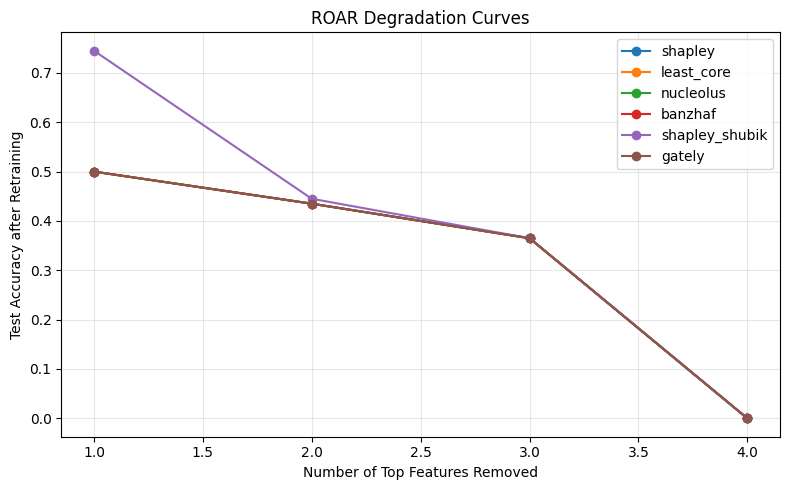


ROAR (Remove and Retrain) Results:
        method  AOPC_ROAR  acc_full
       shapley    0.53500      0.86
    least_core    0.53500      0.86
     nucleolus    0.53500      0.86
       banzhaf    0.53500      0.86
shapley_shubik    0.47125      0.86
        gately    0.53500      0.86


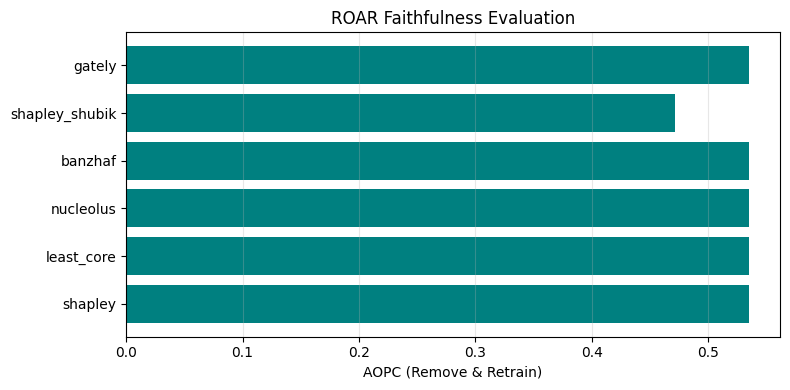

In [ ]:
roar_df = roar_evaluation(
    results, X_train, y_train, X_test, y_test,
    feature_names, MODEL_NAME, scorer
)

print("\nROAR (Remove and Retrain) Results:")
print(roar_df.to_string(index=False))

roar_df.to_csv(
    OUTPUT_DIR / f"{DATASET_NAME}_{MODEL_NAME}_roar_results.csv",
    index=False
)


plt.figure(figsize=(8, 4))
plt.barh(roar_df["method"], roar_df["AOPC_ROAR"], color="teal")
plt.xlabel("AOPC (Remove & Retrain)")
plt.title("ROAR Faithfulness Evaluation")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / f"{DATASET_NAME}_{MODEL_NAME}_roar_plot.png",
    dpi=300, bbox_inches="tight"
)
plt.show()